# Maschinelles Lernen (ML) - Übung 3
# Lineare Regression

In dieser Übung implementieren Sie die einfache lineare Regression auf zwei Arten: einmal über die geschlossene Normalengleichung, einmal über den **Gradientenabstieg** von Grund auf. Der Gradientenabstieg ist dabei der eigentliche Star dieser Übung: Er ist das Trainingsverfahren, auf dem auch die neuronalen Netze der späteren Übungen (7 ff.) aufbauen.

Weitere Hintergründe (Herleitung, Formeln) finden Sie im PDF-Handout zu dieser Übung.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Synthetische Daten

Wir erzeugen uns Daten mit bekannter Ground Truth $y = w_{\text{true}} \cdot x + b_{\text{true}} + \text{Rauschen}$. Da wir die wahren Parameter kennen, können wir später direkt beurteilen, wie gut die geschlossene Lösung bzw.\ der Gradientenabstieg diese wiederfinden.

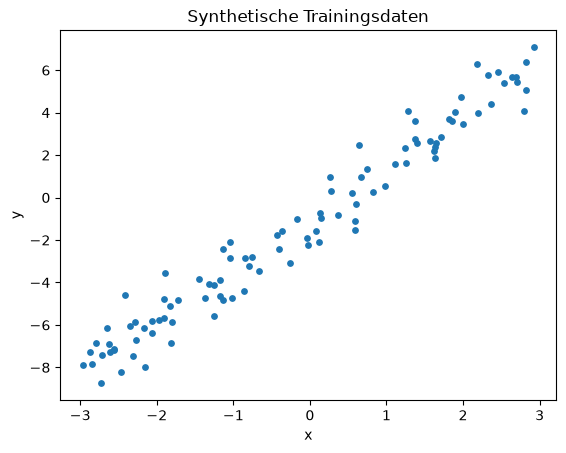

In [7]:
np.random.seed(42)
w_true, b_true = 2.5, -1.0
n_samples = 100

x = np.random.uniform(-3, 3, size=n_samples)
rauschen = np.random.normal(0, 1.0, size=n_samples)
y = w_true * x + b_true + rauschen

plt.scatter(x, y, s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetische Trainingsdaten")
plt.show()

**Aufgabe 1: Geschlossene Lösung (Normalengleichung)**

Implementieren Sie die Funktion `normalengleichung(x, y)`, die die Parameter $(b, w)$ der einfachen linearen Regression über die Normalengleichung berechnet:

a) Erzeugen Sie mit dem Bias-Trick die erweiterte Merkmalsmatrix `X_b` der Form `(n, 2)` (erste Spalte: Einsen für den Bias, zweite Spalte: `x`). Tipp: `np.c_[np.ones_like(x), x]`.

b) Berechnen Sie `theta = (X_b^T X_b)^{-1} X_b^T y` mit `np.linalg.inv` (oder alternativ direkt mit `np.linalg.lstsq(X_b, y, rcond=None)[0]`).

c) Geben Sie `theta` als Tupel `(b, w)` zurück.

In [8]:
def normalengleichung(x, y):
    ### Dein Code kommt hierhin:
    X_b = np.c_[np.ones_like(x), x]
    b, w = np.linalg.matmul(np.linalg.matmul(np.linalg.inv(np.linalg.matmul(np.linalg.matrix_transpose(X_b), X_b)), np.linalg.matrix_transpose(X_b)), y)
    # b, w = np.linalg.lstsq(X_b, y, rcond=None)[0]
    ##########################
    return b, w


b_ne, w_ne = normalengleichung(x, y)
print(f"Normalengleichung: w = {w_ne:.4f}, b = {b_ne:.4f}")
print(f"Wahre Werte:       w = {w_true:.4f}, b = {b_true:.4f}")

Normalengleichung: w = 2.4234, b = -1.0148
Wahre Werte:       w = 2.5000, b = -1.0000


**Aufgabe 2: Gradientenabstieg**

a) Implementieren Sie `mse_loss(x, y, w, b)`, die den mittleren quadratischen Fehler gemäß Gleichung (2) im Handout berechnet.

b) Implementieren Sie `gradients(x, y, w, b)`, die das Gradienten-Tupel `(dw, db)` gemäß Gleichung (4) im Handout berechnet.

c) Implementieren Sie `gradient_descent(x, y, lr, epochs, w_init=0.0, b_init=0.0)`: Startet bei `w_init`, `b_init`, aktualisiert `w` und `b` gemäß Gleichung (5) im Handout über `epochs` Epochen mit fester Lernrate `lr` und gibt am Ende `(w, b, verlauf)` zurück, wobei `verlauf` eine Liste ist, die für jede Epoche `(w, b, loss)` enthält (nützlich für die spätere Visualisierung der Trajektorie).

In [ ]:
def mse_loss(x, y, w, b):
    ### Dein Code kommt hierhin:
    quad_err = (y-(w*x+b)) ** 2
    return np.mean(quad_err)
    ##########################


def gradients(x, y, w, b):
    ### Dein Code kommt hierhin:
    dw, db =  2*np.mean((w*x+b-y)*x), 2*np.mean(w*x+b-y)
    ##########################
    return dw, db


def gradient_descent(x, y, lr, epochs, w_init=0.0, b_init=0.0):
    w, b = w_init, b_init
    verlauf = []
    ### Dein Code kommt hierhin:
    for _ in range(epochs):
        dw, db = gradients(x, y, w, b)
        w -= lr*dw
        b -= lr*db
        verlauf.append((w,b, mse_loss(x, y, w, b)))
    ##########################
    return w, b, verlauf

Gradientenabstieg:  w = 2.4234, b = -1.0148
Normalengleichung:  w = 2.4234, b = -1.0148
Wahre Werte:        w = 2.5000, b = -1.0000


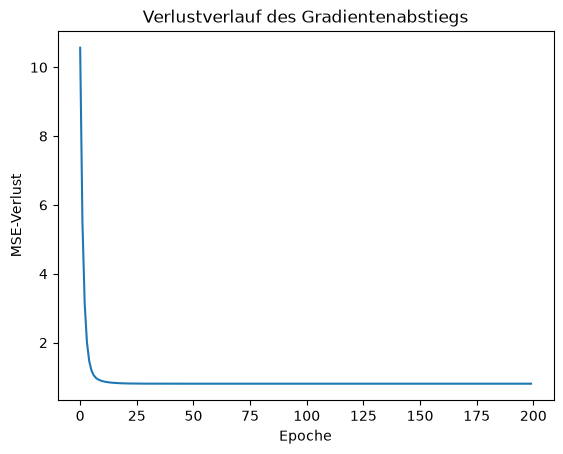

In [10]:
w_gd, b_gd, verlauf = gradient_descent(x, y, lr=0.05, epochs=200)
print(f"Gradientenabstieg:  w = {w_gd:.4f}, b = {b_gd:.4f}")
print(f"Normalengleichung:  w = {w_ne:.4f}, b = {b_ne:.4f}")
print(f"Wahre Werte:        w = {w_true:.4f}, b = {b_true:.4f}")

verluste = [v[2] for v in verlauf]
plt.plot(verluste)
plt.xlabel("Epoche")
plt.ylabel("MSE-Verlust")
plt.title("Verlustverlauf des Gradientenabstiegs")
plt.show()

**Aufgabe 3: Beide Lösungen vergleichen**

Plotten Sie die Datenpunkte zusammen mit den beiden Regressionsgeraden (Normalengleichung und Gradientenabstieg). Wie nah liegen beide Geraden beieinander?

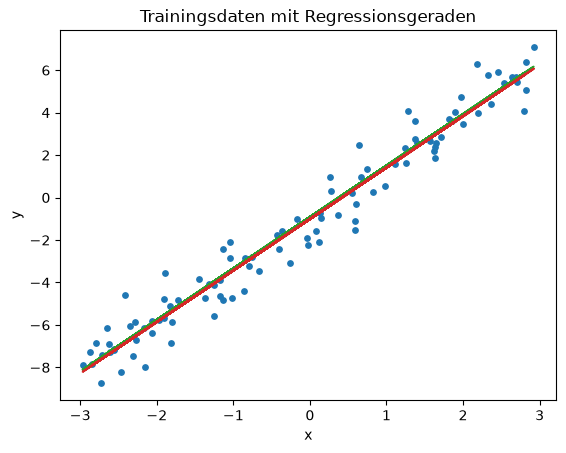

In [25]:
### Dein Code kommt hierhin:
plt.scatter(x, y, s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Trainingsdaten mit Regressionsgeraden")
plt.plot(x, w_ne * x + b_ne + .1, color='tab:green', label='Normalgeradengleichung')
plt.plot(x, w_gd * x + b_gd, color='tab:red', label='Gradientenabstieg')
plt.show()
##########################

*Antwort:* BEIDE GLEICH

**Aufgabe 4: Verlustfläche und Lernraten-Experiment**

a) Berechnen Sie $L(w,b)$ (mit `mse_loss`) über ein Gitter aus `w`- und `b`-Werten (z.B. `w_grid = np.linspace(-1, 6, 100)`, `b_grid = np.linspace(-6, 4, 100)`, mit `np.meshgrid`) und stellen Sie das Ergebnis als Contourplot dar (`plt.contour` bzw.\ `plt.contourf`). Zeichnen Sie den Verlauf Ihrer Gradientenabstiegs-Trajektorie aus Aufgabe 2 (`verlauf`) als Linie hinein.

b) Führen Sie den Gradientenabstieg mit drei unterschiedlichen Lernraten aus (z.B. `0.001`, `0.05` und `0.5`) und plotten Sie den jeweiligen Verlustverlauf über die Epochen gemeinsam in einer Abbildung. Was beobachten Sie, und wie erklären Sie sich den Unterschied?

Text(0, 0.5, 'Bias')

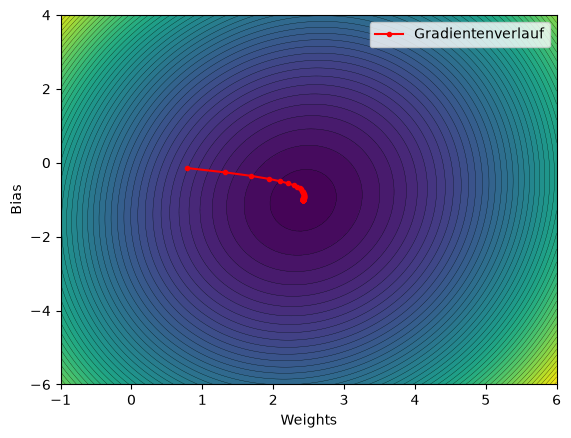

In [12]:
### Dein Code kommt hierhin:
w_grid = np.linspace(-1, 6, 100)
b_grid = np.linspace(-6, 4, 100)
w_v, b_v = np.meshgrid(w_grid, b_grid)
lossgrid = []
for i in range(w_v.__len__()):
    lossrow = []
    for j in range(b_v.__len__()):
        lossrow.append(mse_loss(x,y, w_v[i, j], b_v[i,j]))
    lossgrid.append(lossrow)

plt.contourf(w_v,b_v, lossgrid, levels=50)        
plt.contour(w_v,b_v, lossgrid, levels=50, colors="k", linewidth=0.2)

plt.plot([v[0] for v in verlauf], [v[1] for v in verlauf], "r.-", label="Gradientenverlauf")
plt.legend()

plt.xlabel("Weights")
plt.ylabel("Bias")
##########################

Text(0, 0.5, 'Bias')

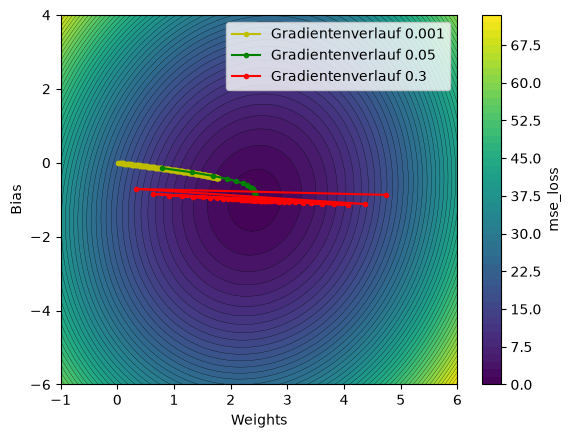

In [26]:
### Dein Code kommt hierhin:
dum, dum2, verlauf1 = gradient_descent(x, y, lr=0.3, epochs=200)
dum, dum2, verlauf2 = gradient_descent(x, y, lr=0.05, epochs=200)
dum, dum2, verlauf3 = gradient_descent(x, y, lr=0.001, epochs=200)

plt.contourf(w_v,b_v, lossgrid, levels=50)        
plt.colorbar(label="mse_loss")
plt.contour(w_v,b_v, lossgrid, levels=50, colors="k", linewidth=0.2)

plt.plot([v[0] for v in verlauf3], [v[1] for v in verlauf3], "y.-", label="Gradientenverlauf 0.001")
plt.plot([v[0] for v in verlauf2], [v[1] for v in verlauf2], "g.-", label="Gradientenverlauf 0.05")
plt.plot([v[0] for v in verlauf1], [v[1] for v in verlauf1], "r.-", label="Gradientenverlauf 0.3")
plt.legend()

plt.xlabel("Weights")
plt.ylabel("Bias")
##########################

*Antwort:*  lr = 0.001 ist zu klein und erreicht in 200 Epochs nicht das Minimum
            lr = 0.5 ist viel,viel zu froß und überspringt das Minimum nach sonstwohin

**Optional: Validierung mit `scikit-learn` auf echten Daten**

Vergleichen Sie Ihre eigene Implementierung mit `sklearn.linear_model.LinearRegression` auf dem `load_diabetes`-Datensatz, beschränkt auf ein einzelnes Merkmal (BMI, Spalte `"bmi"`).

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

### Dein Code kommt hierhin:

##########################